# Assignment 7: Classification Analysis | Pair Assignment

**Goal:** build and compare a **Decision Tree** and a **Naive Bayes** classifier on your
group's dataset, then report what you found. EAch pair will choose one dataset from the following table and do the following.


Hints are provided in the cells marked `# TODO`. If you get stuck on syntax, check the code examples form this week.

> **Replace the loan_sample.cs with your chosen Kaggle dataset** and update the target column.

## Your dataset

| Group dataset | Example classification task | Target column | Kaggle link |
|---|---|---|---|
| SF Crime | Predict crime category, or district | `Category` / `PdDistrict` | https://www.kaggle.com/competitions/sf-crime/data
| NASA Asteroids | Predict if an asteroid is hazardous | `Hazardous` | https://www.kaggle.com/datasets/shrutimehta/nasa-asteroids-classification
| Hotel Booking | Predict if a booking is cancelled, or hotel type | `is_canceled` / `hotel` | https://www.kaggle.com/datasets/jessemostipak/hotel-booking-demand

Use a Decision Tree for one task and Naive Bayes for the other (or, for Asteroids, run
both on the same task and compare). Keep notes as you go; you will need them for the report
at the bottom.

## Know your dataset before you start | Each pair will choose one of the following dataset

Read the block for your group's dataset first. It tells you what you are actually
predicting and the specific things to watch for at each step, so you are not surprised
halfway through.

### SF Crime, predicting crime category or district

**What you are figuring out:** can the time and place of an incident predict what kind of
crime it was, or which police district it happened in? You are turning raw incident logs
into useful predictors.

- **Exploration:** this file is huge (about 1 million rows). Take a random sample (say 50,000 rows) so your code runs fast. Check how many distinct crime categories exist.
- **Preprocessing:** the timestamp is not useful as text. Pull `hour`, `day of week`, and `month` out of it into their own numeric columns. If there are too many crime categories, group the rare ones into an "Other" bucket so the model is not splitting on dozens of tiny classes. Keep latitude and longitude; they are strong predictors.
- **Build models:** Decision Tree for one task (for example, category) and Naive Bayes for the other (district).
- **Evaluate:** with many classes, accuracy alone is thin. Look at the confusion matrix to see which categories get mixed up.

### NASA Asteroids, predicting hazardous (yes / no)

**What you are figuring out:** from an asteroid's size and orbital measurements, can you
predict whether NASA flags it as hazardous? This is the cleanest Decision Tree versus
Naive Bayes comparison of the three.

- **Exploration:** check the class balance first. Only about 16% are hazardous, so a model that always guesses "not hazardous" is already about 84% accurate. That is the baseline you must beat, and it is why accuracy alone will mislead you.
- **Preprocessing:** drop columns that carry no signal, such as `id` and `name`. The features are on very different scales (diameter versus orbital period), so apply feature scaling. This matters a lot for Naive Bayes.
- **Build models:** run both a Decision Tree and Naive Bayes on the same task and compare them directly.
- **Evaluate:** because the classes are imbalanced, report precision and recall for the "hazardous" class, not just accuracy. Recall matters most here: a missed hazardous asteroid is the costly error.

### Hotel Booking, predicting cancellation or hotel type

**What you are figuring out:** can booking details predict whether a reservation will be
cancelled, or whether it is a city versus resort hotel? This one is encoding-heavy.

- **Exploration:** check the cancellation rate (the classes may be imbalanced) and scan which columns are text versus numeric.
- **Preprocessing:** many columns are categorical and need encoding (`get_dummies` or `LabelEncoder`). Date columns are not useful raw; pull out useful pieces like the month. Watch for NULLs that are actually meaningful: a missing travel-agent value usually means "no agent," not bad data, so do not blindly drop those rows.
- **Build models:** Decision Tree for one task, Naive Bayes for the other.
- **Evaluate:** if cancellations are the minority class, look at precision and recall for cancellations, not just overall accuracy.

In [12]:
# Prerequisites
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report

print("Ready.")

Ready.


In [13]:
%matplotlib inline
import os
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

## Step 1 - Data exploration

Load your data and get to know it: how many rows and columns, what the columns mean, and
how balanced the classes are. Class balance matters: if 90% of rows are one class, a model
can look accurate just by guessing that class every time.

In [14]:
# GIVEN: load the dataset. Change this path to your group's file when you have it.
df = pd.read_csv("./nasa.csv")

# Set this to the name of the column you are predicting.
target = "Hazardous"

df.head()

,Neo Reference ID,Name,Absolute Magnitude,Est Dia in KM(min),Est Dia in KM(max),Est Dia in M(min),Est Dia in M(max),Est Dia in Miles(min),Est Dia in Miles(max),Est Dia in Feet(min),...,Asc Node Longitude,Orbital Period,Perihelion Distance,Perihelion Arg,Aphelion Dist,Perihelion Time,Mean Anomaly,Mean Motion,Equinox,Hazardous
0,3703080,3703080,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,314.373913,609.599786,0.808259,57.257470,2.005764,2.458162e+06,264.837533,0.590551,J2000,True
1,3723955,3723955,21.3,0.146068,0.326618,146.067964,326.617897,0.090762,0.202951,479.225620,...,136.717242,425.869294,0.718200,313.091975,1.497352,2.457795e+06,173.741112,0.845330,J2000,False
2,2446862,2446862,20.3,0.231502,0.517654,231.502122,517.654482,0.143849,0.321655,759.521423,...,259.475979,643.580228,0.950791,248.415038,1.966857,2.458120e+06,292.893654,0.559371,J2000,True
3,3092506,3092506,27.4,0.008801,0.019681,8.801465,19.680675,0.005469,0.012229,28.876199,...,57.173266,514.082140,0.983902,18.707701,1.527904,2.457902e+06,68.741007,0.700277,J2000,False
4,3514799,3514799,21.6,0.127220,0.284472,127.219879,284.472297,0.079051,0.176763,417.388066,...,84.629307,495.597821,0.967687,158.263596,1.483543,2.457814e+06,135.142133,0.726395,J2000,True


In [15]:
# Explore the data
print("Shape:", df.shape)
print("Missing values:", df.isna().sum().sum())
print()
df.info()
print()
print(df[target].value_counts())
print()
print(df[target].value_counts(normalize=True).round(3))
df.describe().T.head(12)

Shape: (4687, 40)
Missing values: 0

<class 'pandas.DataFrame'>
RangeIndex: 4687 entries, 0 to 4686
Data columns (total 40 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Neo Reference ID              4687 non-null   int64  
 1   Name                          4687 non-null   int64  
 2   Absolute Magnitude            4687 non-null   float64
 3   Est Dia in KM(min)            4687 non-null   float64
 4   Est Dia in KM(max)            4687 non-null   float64
 5   Est Dia in M(min)             4687 non-null   float64
 6   Est Dia in M(max)             4687 non-null   float64
 7   Est Dia in Miles(min)         4687 non-null   float64
 8   Est Dia in Miles(max)         4687 non-null   float64
 9   Est Dia in Feet(min)          4687 non-null   float64
 10  Est Dia in Feet(max)          4687 non-null   float64
 11  Close Approach Date           4687 non-null   str    
 12  Epoch Date Close Approach     4687 n

,count,mean,std,min,25%,50%,75%,max
Neo Reference ID,4687.0,3.272298e+06,5.486011e+05,2.000433e+06,3.097594e+06,3.514799e+06,3.690060e+06,3.781897e+06
Name,4687.0,3.272298e+06,5.486011e+05,2.000433e+06,3.097594e+06,3.514799e+06,3.690060e+06,3.781897e+06
Absolute Magnitude,4687.0,2.226786e+01,2.890972e+00,1.116000e+01,2.010000e+01,2.190000e+01,2.450000e+01,3.210000e+01
Est Dia in KM(min),4687.0,2.046042e-01,3.695734e-01,1.010543e-03,3.346224e-02,1.108039e-01,2.538370e-01,1.557955e+01
Est Dia in KM(max),4687.0,4.575089e-01,8.263912e-01,2.259644e-03,7.482384e-02,2.477650e-01,5.675969e-01,3.483694e+01
Est Dia in M(min),4687.0,2.046042e+02,3.695734e+02,1.010543e+00,3.346224e+01,1.108039e+02,2.538370e+02,1.557955e+04
Est Dia in M(max),4687.0,4.575089e+02,8.263912e+02,2.259644e+00,7.482384e+01,2.477650e+02,5.675969e+02,3.483694e+04
Est Dia in Miles(min),4687.0,1.271351e-01,2.296422e-01,6.279224e-04,2.079246e-02,6.885032e-02,1.577270e-01,9.680682e+00
Est Dia in Miles(max),4687.0,2.842828e-01,5.134956e-01,1.404077e-03,4.649336e-02,1.539540e-01,3.526882e-01,2.164666e+01
Est Dia in Feet(min),4687.0,6.712737e+02,1.212511e+03,3.315431e+00,1.097842e+02,3.635298e+02,8.327987e+02,5.111402e+04


## Step 2 - Preprocessing

Get the data ready for the models. You will typically need to:

- Drop columns that are just identifiers or are not useful (e.g. an ID column).
- Handle missing values (fill numeric columns with the median, text columns with the mode).
- Encode categorical (text) columns into numbers with `pd.get_dummies(...)` or `LabelEncoder`.
- Separate the target `y` from the features `X`, then split into train and test sets.

In [16]:
# Drop columns that carry no signal or just repeat another column
drop_cols = [
    "Neo Reference ID", "Name",                              # identifiers
    "Orbiting Body", "Equinox",                              # same value in every row
    "Close Approach Date", "Epoch Date Close Approach",      # dates, not useful raw
    "Orbit Determination Date",
    "Est Dia in M(min)", "Est Dia in M(max)",                # same diameter in other units
    "Est Dia in Miles(min)", "Est Dia in Miles(max)",
    "Est Dia in Feet(min)", "Est Dia in Feet(max)",
    "Relative Velocity km per hr", "Miles per hour",         # same velocity in other units
    "Miss Dist.(lunar)", "Miss Dist.(kilometers)", "Miss Dist.(miles)",  # same distance in other units
]
data = df.drop(columns=drop_cols).copy()

# Handle missing values (there are none in this file, but the loop is here to be safe)
for col in data.columns:
    if data[col].isna().any():
        if pd.api.types.is_numeric_dtype(data[col]):
            data[col] = data[col].fillna(data[col].median())
        else:
            data[col] = data[col].fillna(data[col].mode()[0])

print("Columns kept:", data.shape[1] - 1, "features + target")

Columns kept: 21 features + target


In [17]:
# Build X (features) and y (target), then encode any categorical columns
y = data[target].astype(int)          # True/False -> 1/0
X = pd.get_dummies(data.drop(columns=[target]), drop_first=True)
print(X.shape)

(4687, 21)


In [18]:
# Split into training and test sets (stratify keeps the 16% hazardous share in both)
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=1, stratify=y)

# Feature scaling: fit on train only, then apply to both
scaler = StandardScaler()
X_train_s = scaler.fit_transform(X_train)
X_test_s = scaler.transform(X_test)

print(X_train.shape, X_test.shape)

(3515, 21) (1172, 21)


## Step 3 - Build the models

Each classifier is only a few lines: create it, then call `.fit(X_train, y_train)`.

In [19]:
# Train a Decision Tree
dtree = DecisionTreeClassifier(max_depth=5, random_state=1)
dtree.fit(X_train_s, y_train)

,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",5
,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",1
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in 

In [20]:
# Train a Naive Bayes classifier
nb_model = GaussianNB()
nb_model.fit(X_train_s, y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[2949., 566.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.84,0.16]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,21
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 21)","[[ 0.14,-0.05,-0.05,...,-0.02,-0.02,-0. ], [-0.73, 0.28, 0.28,..., 0.08, 0.1 , 0. ]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 21)","[[1.03,1.06,1.06,...,1.05,1.01,0.99], [0.22,0.6 ,0.6 ,...,0.73,0.93,1.05]]"


## Step 4 - Evaluate and compare

For **each** model, predict on the test set and report:

- accuracy (`accuracy_score`)
- the confusion matrix (`ConfusionMatrixDisplay.from_predictions`)
- precision, recall, and F1 (`classification_report`)

Then compare: which model is more accurate, and what do the precision and recall for the
class you care about tell you?

In [21]:
# Evaluate the Decision Tree
dt_pred = dtree.predict(X_test_s)
dt_acc = accuracy_score(y_test, dt_pred)
print("Accuracy:", round(dt_acc, 4))


Accuracy: 0.994


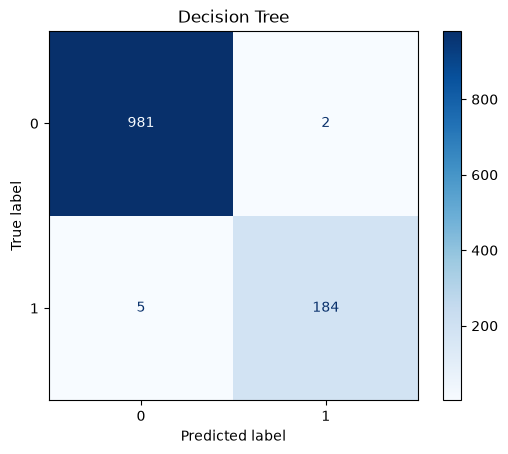

               precision    recall  f1-score   support

Not hazardous       0.99      1.00      1.00       983
    Hazardous       0.99      0.97      0.98       189

     accuracy                           0.99      1172
    macro avg       0.99      0.99      0.99      1172
 weighted avg       0.99      0.99      0.99      1172



In [22]:
ConfusionMatrixDisplay.from_predictions(y_test, dt_pred, cmap="Blues")
plt.title("Decision Tree")
plt.show()
print(classification_report(y_test, dt_pred, target_names=["Not hazardous", "Hazardous"]))



In [23]:
# Which features did the tree rely on?
imp = pd.Series(dtree.feature_importances_, index=X.columns).sort_values(ascending=False)
print(imp.head(5).round(3))

Est Dia in KM(min)            0.794
Minimum Orbit Intersection    0.193
Orbit ID                      0.005
Mean Anomaly                  0.004
Est Dia in KM(max)            0.002
dtype: float64


Accuracy: 0.9522


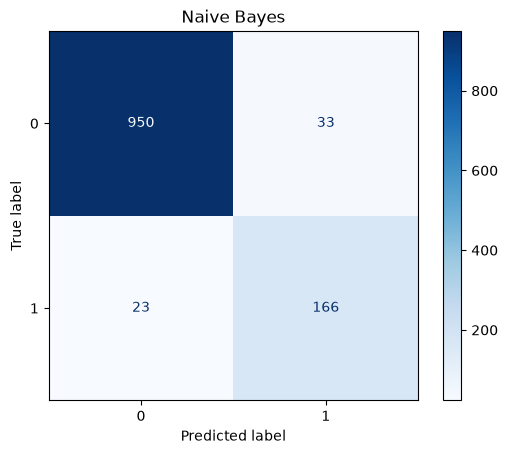

               precision    recall  f1-score   support

Not hazardous       0.98      0.97      0.97       983
    Hazardous       0.83      0.88      0.86       189

     accuracy                           0.95      1172
    macro avg       0.91      0.92      0.91      1172
 weighted avg       0.95      0.95      0.95      1172



In [24]:
# Evaluate the Naive Bayes model
nb_pred = nb_model.predict(X_test_s)
nb_acc = accuracy_score(y_test, nb_pred)
print("Accuracy:", round(nb_acc, 4))
ConfusionMatrixDisplay.from_predictions(y_test, nb_pred, cmap="Blues")
plt.title("Naive Bayes")
plt.show()
print(classification_report(y_test, nb_pred, target_names=["Not hazardous", "Hazardous"]))

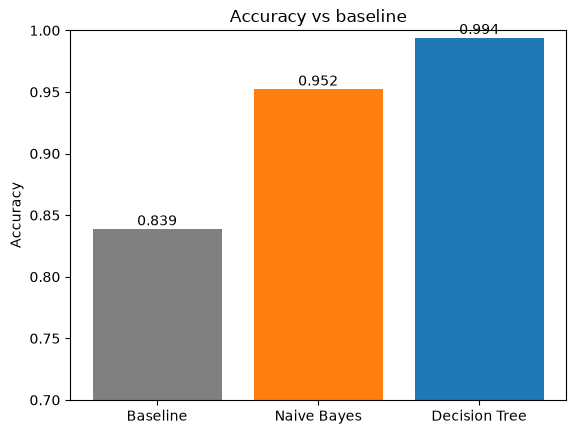

In [25]:
# Compare both models against the "always guess not hazardous" baseline
baseline = y_test.value_counts(normalize=True).max()

names = ["Baseline", "Naive Bayes", "Decision Tree"]
scores = [baseline, nb_acc, dt_acc]

plt.bar(names, scores, color=["gray", "tab:orange", "tab:blue"])
plt.ylim(0.7, 1.0)
plt.ylabel("Accuracy")
plt.title("Accuracy vs baseline")
for i, s in enumerate(scores):
    plt.text(i, s + 0.003, f"{s:.3f}", ha="center")
plt.show()

## Step 5 - Findings

Write your answers here as you work.

1. **Preprocessing / data reduction** - what did you have to clean, drop, encode, or sample, and why?

   *Your answer:* The file had 4,688 rows, 40 columns, and no missing values. I cut it down to 21 predictors by dropping the ID columns 'Neo Reference ID', 'Name', two columns that are the same in every row 'Orbiting Body', Equinox', the date columns, and the repeated unit columns, since they say the same thing as a column I kept. No encoding was needed because everything left was numeric. I applied 'StandardScaler' (fit on the training data only) because the features are on very different scales, which matters for Naive Bayes. 

2. **Data used** - which features did you select as predictors, and why those?

   *Your answer:* I kept the asteroid's size (Absolute Magnitude, Est Dia in KM min/max), how fast and close it passes (Relative Velocity km per sec, Miss Dist.), and its orbit measurements (Minimum Orbit Intersection, eccentricity, semi-major axis, inclination, orbital period, perihelion/aphelion values, etc.). Size and orbit are what you would expect NASA to use when deciding if something is hazardous, so I kept all of them and let the models sort out which matter.

3. **Findings** - what did the analysis reveal about the data itself (patterns, surprises)?

   *Your answer:* Only 16.1% of asteroids are hazardous, so always guessing "not hazardous" is already about 84% accurate. The Decision Tree leaned almost entirely on two features: estimated diameter (about 79% of the importance) and 'Minimum Orbit Intersection' (about 19%). That makes sense because "hazardous" is basically a rule about how big an asteroid is and how close its orbit gets to Earth's, so the label is closely tied to those two columns. That is also why the scores are so high.

4. **Decision Tree vs Naive Bayes** - which performed better on your task, and what are the
   strengths and shortcomings of each one here?

   *Your answer:* The Decision Tree won clearly: 99.4% accuracy vs 95.2% for Naive Bayes. For the hazardous class the tree had precision 0.99 and recall 0.97 (it missed 5 of 189 hazardous asteroids), while Naive Bayes had precision 0.83 and recall 0.88 (it missed 23 and raised 33 false alarms). Missing hazardous asteroids is worse than mislabling non-hazardous ones, so the tree is still a better choice. It is good at this because the label comes from thresholds on a couple of features, and it is easy to read. Naive Bayes is fast and simple, but it assumes the features are independent given the class, and many of these are strongly related (diameter, magnitude, and several orbit values), so that assumption does not hold well and it loses accuracy.

5. **Challenges** - What was difficult, and how did you handle it?

   *Your answer:* The hardest part was deciding which of the 40 columns to keep, since many were the same measurement in different units. I removed the duplicates so the models were not counting one thing several times. The imbalance was the other issue: accuracy alone looks great even for a useless model, so I compared against the 83.9% baseline and looked at precision and recall for the hazardous class instead.


## Submission checklist

- This notebook (renamed `Last_First_Assignment7.ipynb`), with all cells run and output showing
- Link to your GitHub repository